In [18]:
from Bio import Phylo
import iplotx as ipx
from io import StringIO
import matplotlib.pyplot as plt


In [16]:
newick = "(mythological,(confusion_metaphorics,(scientific_complexity_metaphorics,medical_anatomical)));"
tree = Phylo.read(StringIO(newick), "newick")#%%

Tree(rooted=False, weight=1.0)
    Clade()
        Clade(name='mythological')
        Clade()
            Clade(name='confusion_metaphorics')
            Clade()
                Clade(name='scientific_complexity_metaphorics')
                Clade(name='medical_anatomical')


In [9]:
Phylo.draw_ascii(tree)

  _____________ mythological
_|
 |              ______________ confusion_metaphorics
 |_____________|
               |               ______________ scientific_complexity_metaphorics
               |______________|
                              |______________ medical_anatomical



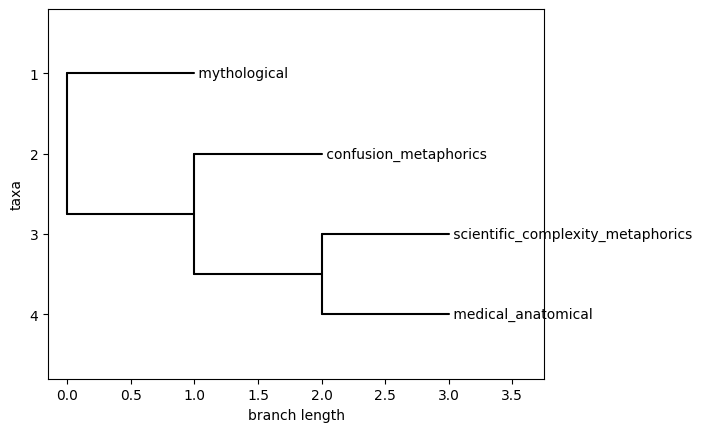

In [10]:
Phylo.draw(tree)

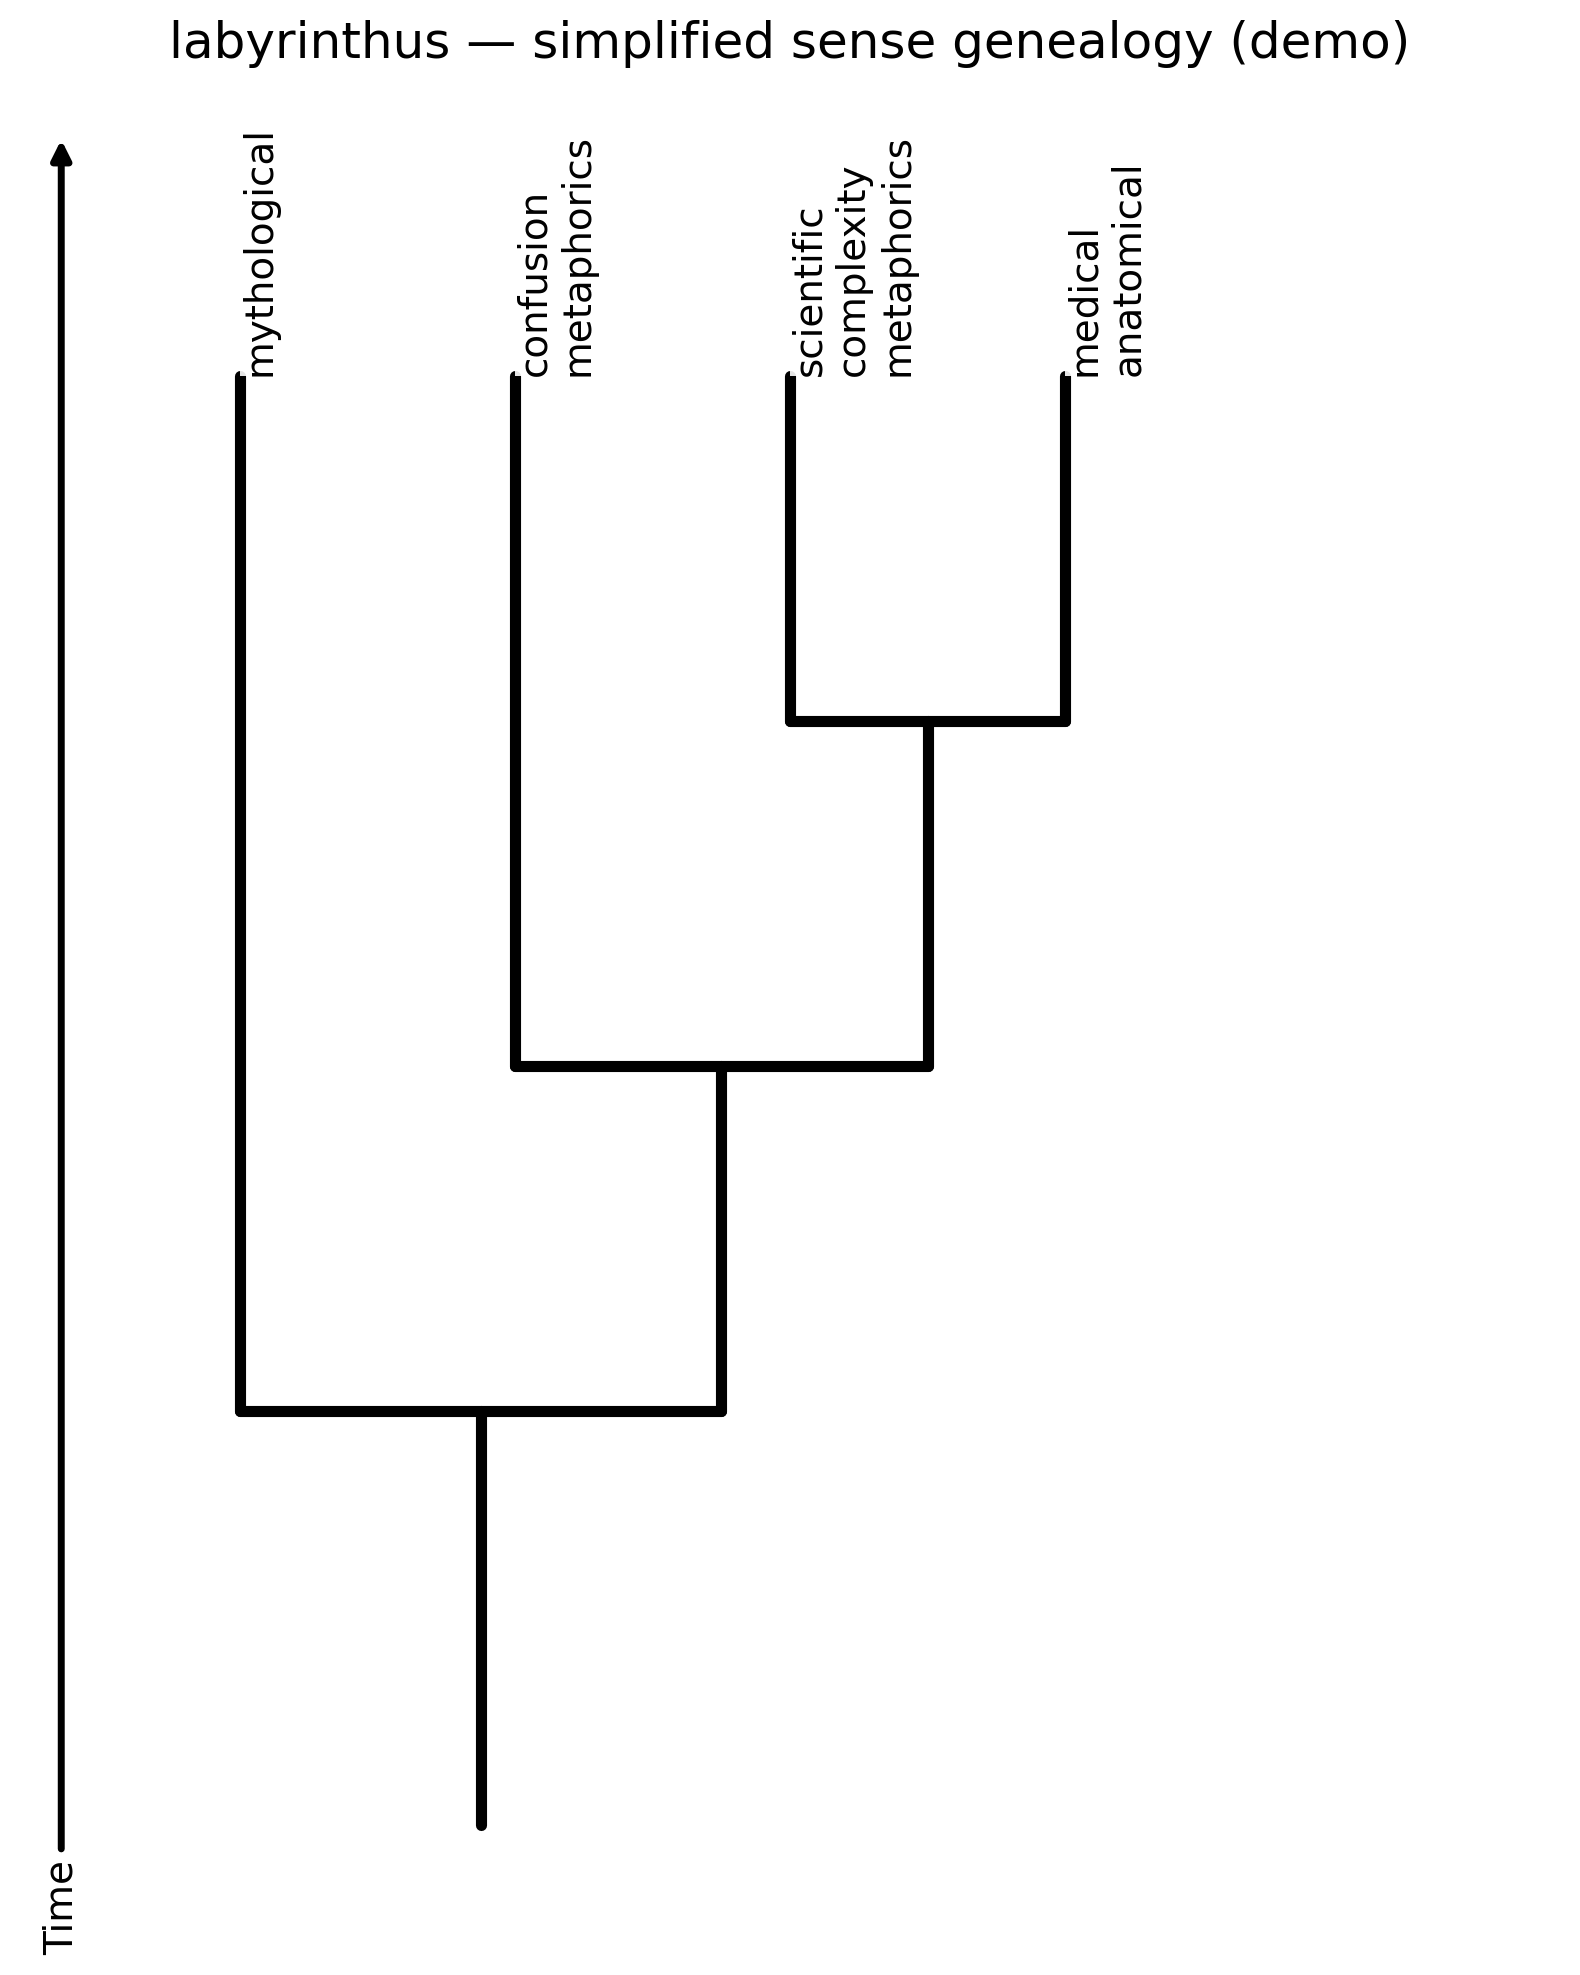

In [31]:
def draw_tree_vertical_pretty(tree, *, title=None,
                             leaf_spacing=3.2,
                             linewidth=4.0,
                             label_size=14,
                             figsize=(8, 10),
                             dpi=200,
                             show_time_arrow=True,
                             wrap=True,
                             align_tips=True,
                             root_stem=0.8):   # <<< NEW: trunk length before first split
    terminals = tree.get_terminals()

    x_leaf = {t: i * leaf_spacing for i, t in enumerate(terminals)}
    y_raw = {clade: tree.distance(tree.root, clade) for clade in tree.find_clades()}
    y_tip = max(y_raw.values()) if align_tips else None

    x = {t: x_leaf[t] for t in terminals}

    def compute_x(clade):
        if clade in x:
            return x[clade]
        xv = [compute_x(k) for k in clade.clades]
        x[clade] = sum(xv) / len(xv)
        return x[clade]

    compute_x(tree.root)

    fig, ax = plt.subplots(figsize=figsize, dpi=dpi)

    def y_draw(clade):
        if align_tips and clade.is_terminal():
            return y_tip
        return y_raw[clade]

    # --- draw ROOT STEM (below root) ---
    if root_stem and root_stem > 0:
        xr = x[tree.root]
        ax.plot([xr, xr], [-root_stem, 0], lw=linewidth, color="black", solid_capstyle="round")

    def draw_edge(parent, child):
        xp, yp = x[parent], y_draw(parent)
        xc, yc = x[child], y_draw(child)
        ax.plot([xp, xc], [yp, yp], lw=linewidth, color="black", solid_capstyle="round")
        ax.plot([xc, xc], [yp, yc], lw=linewidth, color="black", solid_capstyle="round")

    def walk(parent):
        for child in parent.clades:
            draw_edge(parent, child)
            walk(child)

    walk(tree.root)

    # labels
    for t in terminals:
        label = t.name or ""
        if wrap:
            label = wrap_label(label, max_lines=3)
        ax.text(
            x[t], y_draw(t), label,
            va="bottom", ha="left",
            fontsize=label_size, fontfamily="DejaVu Sans",
            rotation=90,
            bbox=dict(facecolor="white", edgecolor="none", pad=0, alpha=0.9),
        )

    y_max = y_tip if align_tips else max(y_raw.values())
    ax.set_ylim(-root_stem - 0.2, y_max + 0.8)   # <<< include stem
    ax.set_xlim(-leaf_spacing * 0.8, x_leaf[terminals[-1]] + leaf_spacing * 1.8)

    ax.set_xticks([]); ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)

    if title:
        ax.set_title(title, fontsize=18, pad=15, fontfamily="DejaVu Sans")

    if show_time_arrow:
        ymin, ymax = ax.get_ylim()
        ax.annotate(
            "Time",
            xy=(-leaf_spacing * 0.65, ymax - 0.1),
            xytext=(-leaf_spacing * 0.65, ymin + 0.1),
            arrowprops=dict(arrowstyle="-|>", lw=2.5, color="black"),
            ha="center", va="top",
            rotation=90, fontsize=14,
        )

    plt.tight_layout()
    return fig, ax

draw_tree_vertical_pretty(
    tree,
    title="labyrinthus — simplified sense genealogy (demo)",
    leaf_spacing=3.4,
    root_stem=1.2,   # adjust “time with only the ancestor”
    align_tips=True,
)
plt.show()

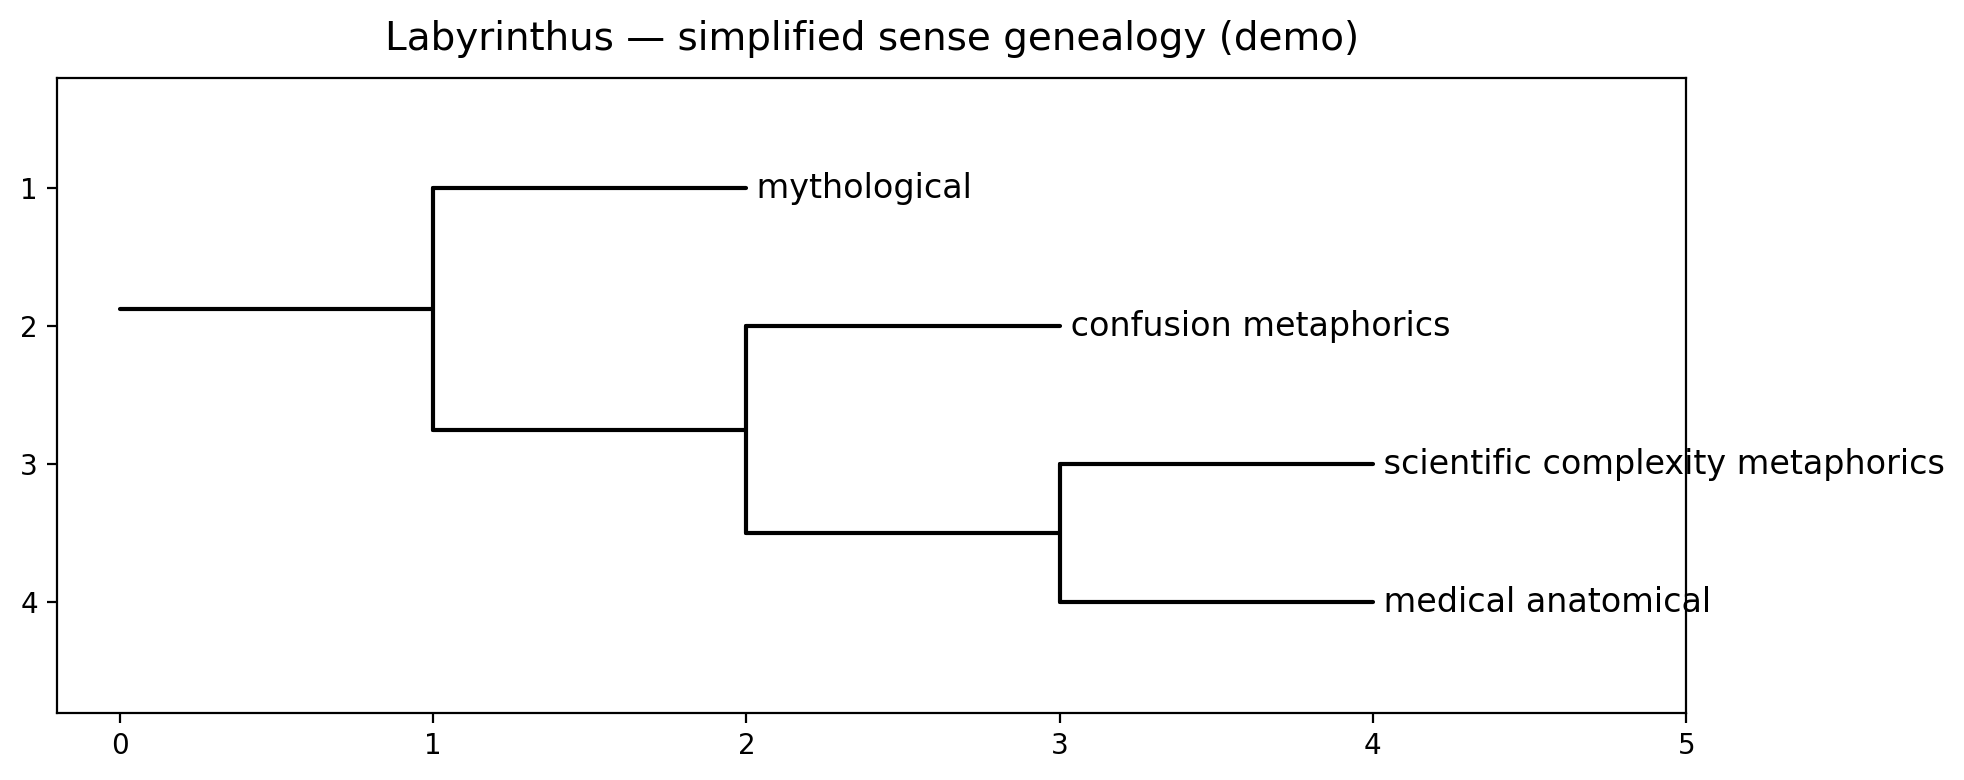

In [19]:
# Optional: give the tree a bit of branch length so it doesn't look cramped
# (Newick without lengths defaults to 0.0; drawing still works, but spacing can be tight)
for clade in tree.find_clades():
    if clade.branch_length is None:
        clade.branch_length = 1.0

# Plot
fig = plt.figure(figsize=(10, 4), dpi=200)
ax = fig.add_subplot(1, 1, 1)

Phylo.draw(
    tree,
    axes=ax,
    do_show=False,
    show_confidence=False,
)

# Aesthetics: thicker branches
for line in ax.get_lines():
    line.set_linewidth(2.0)

# Aesthetics: nicer label font + alignment tweaks
for txt in ax.texts:
    txt.set_fontsize(12)
    txt.set_fontfamily("DejaVu Sans")
    # Optional: turn underscores into spaces for slides
    txt.set_text(txt.get_text().replace("_", " "))

ax.set_title("Labyrinthus — simplified sense genealogy (demo)", fontsize=14, pad=10)
ax.set_xlabel("")  # remove
ax.set_ylabel("")  # remove

plt.tight_layout()
plt.show()

In [11]:
# convert to PhyloXML, which allows more annotations and richer structure
tree = tree.as_phyloxml()

In [12]:
tree.root.color = "red"

In [13]:
# color most recent common ancestor of a set of terminals
mrca = tree.common_ancestor({"E", "F"})
mrca.color = "blue"

ValueError: target 'F' is not in this tree

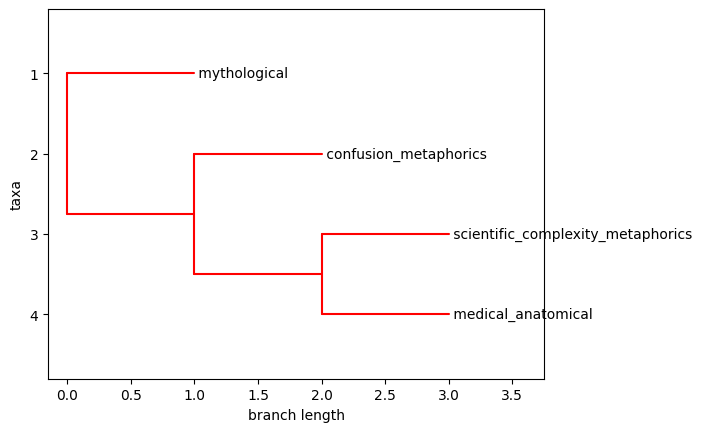

In [14]:
Phylo.draw(tree)

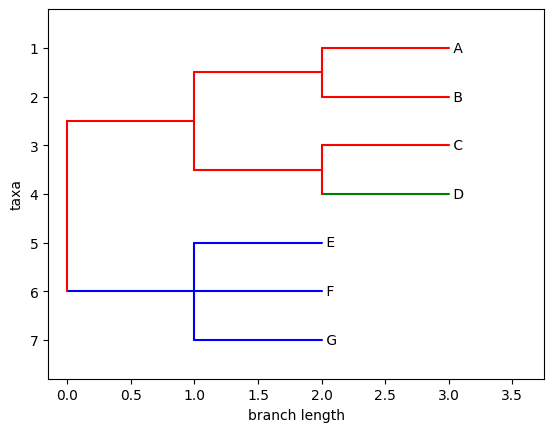

In [14]:
# color by clade indeces, starting from root [0]and the top
tree.clade[0,1,1].color = "green"
Phylo.draw(tree)

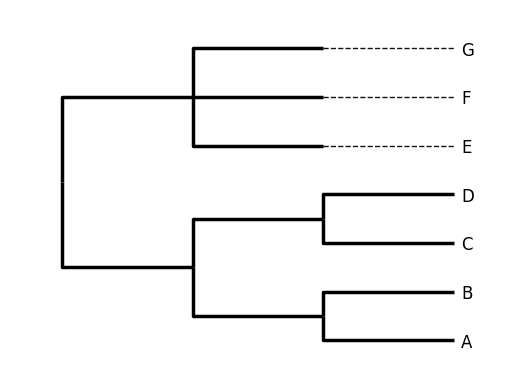

In [16]:
# plot with iplotx
ipx.tree(tree, leaf_deep=True, leaf_labels=True, style="tree")